# Functions

Functions are a bundle or block of code that only executes when we call the function

In [ ]:
def function_name():

## Calculate Tax function

In [2]:
def calculate_total(amount):
    total = amount+(amount*.075)
    return total


# Invoke a function
results = calculate_total(100)

print(results)

107.5


In [3]:
# Calculate the tip amount

def calculate_tip(amount, tipPercentage):
    tipCalc = amount * tipPercentage / 100
    return tipCalc

results = calculate_tip(45, 20)

print(results)

9.0


In [4]:
# Generate an invoice

def generateInvoice(client, project, amount, dueDate):
    print(f"Hello {client}, your invoice for {project} is ${amount:.2f} and is due on {dueDate}.")

# Example of how to use it
generateInvoice("Acme Corp", "Website Redesign", 1500.00, "2026-11-20")
generateInvoice("Beta LLC", "Mobile App Dev", 3000.00, "2026-12-20")

Hello Acme Corp, your invoice for Website Redesign is $1500.00 and is due on 2026-11-20.
Hello Beta LLC, your invoice for Mobile App Dev is $3000.00 and is due on 2026-12-20.


# Matplotlib

## Olympics analysis and visualization

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

resultsdf = pd.read_csv('http://128.198.162.191/dataFiles/OLYMPICS/olympics_1896-2024.csv')



In [6]:
resultsdf.info()

<class 'pandas.DataFrame'>
RangeIndex: 24012 entries, 0 to 24011
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Year        24012 non-null  int64
 1   City        24012 non-null  str  
 2   Sport       24012 non-null  str  
 3   Discipline  24012 non-null  str  
 4   Athlete     20388 non-null  str  
 5   Country     24012 non-null  str  
 6   Gender      24012 non-null  str  
 7   EventType   24012 non-null  str  
 8   Medal       24012 non-null  str  
dtypes: int64(1), str(8)
memory usage: 1.6 MB


In [8]:
resultsdf.head()

,Year,City,Sport,Discipline,Athlete,Country,Gender,EventType,Medal
0,2024,Paris,Cycling Road,Men Individual Time Trial,Evenepoel Remco,Belgium,Male,Athlete,Gold
1,2024,Paris,Cycling Road,Men Individual Time Trial,Ganna Filippo,Italy,Male,Athlete,Silver
2,2024,Paris,Cycling Road,Men Individual Time Trial,Van Aert Wout,Belgium,Male,Athlete,Bronze
3,2024,Paris,Cycling Road,Women Individual Time Trial,Brown Grace,Australia,Female,Athlete,Gold
4,2024,Paris,Cycling Road,Women Individual Time Trial,Henderson Anna,Great Britain,Female,Athlete,Silver


## How many medals has each Country won?

In [23]:
medalsByCountry = resultsdf.groupby('Country')['Medal'].count().sort_values(ascending=False)

medalsByCountry

Country
United States of America    3424
Germany                     1280
Soviet Union                1272
Great Britain               1207
France                      1139
                            ... 
Paraguay                       1
Guyana                         1
Iraq                           1
Samoa                          1
Sudan                          1
Name: Medal, Length: 162, dtype: int64

### Visualize the data

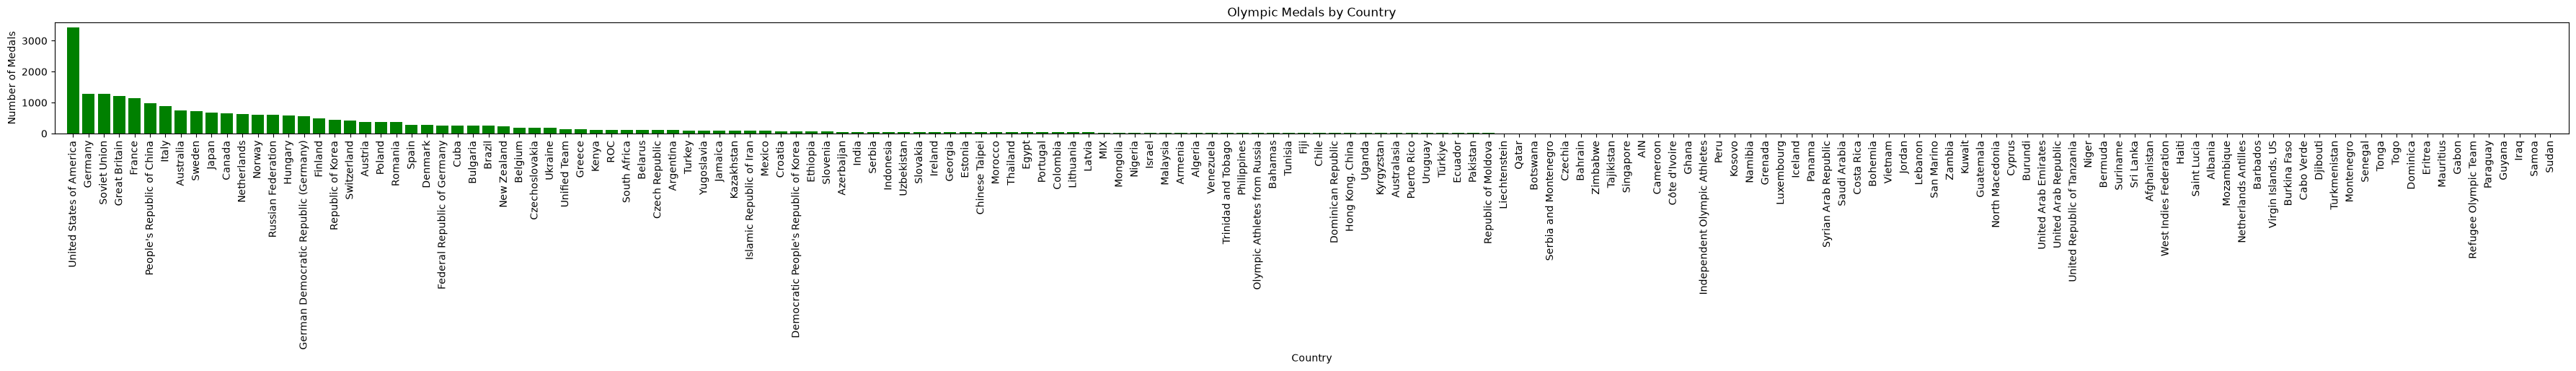

In [24]:
# Format the chart
plt.figure(figsize=(45,2))

# Format a bar chart
plt.bar(medalsByCountry.index, medalsByCountry.values, color='green')

plt.title("Olympic Medals by Country")
plt.xlabel('Country')
plt.ylabel('Number of Medals')
plt.xticks(rotation = 90)

# We can force the graph to start at 0.
plt.margins(x=.005)


plt.show()

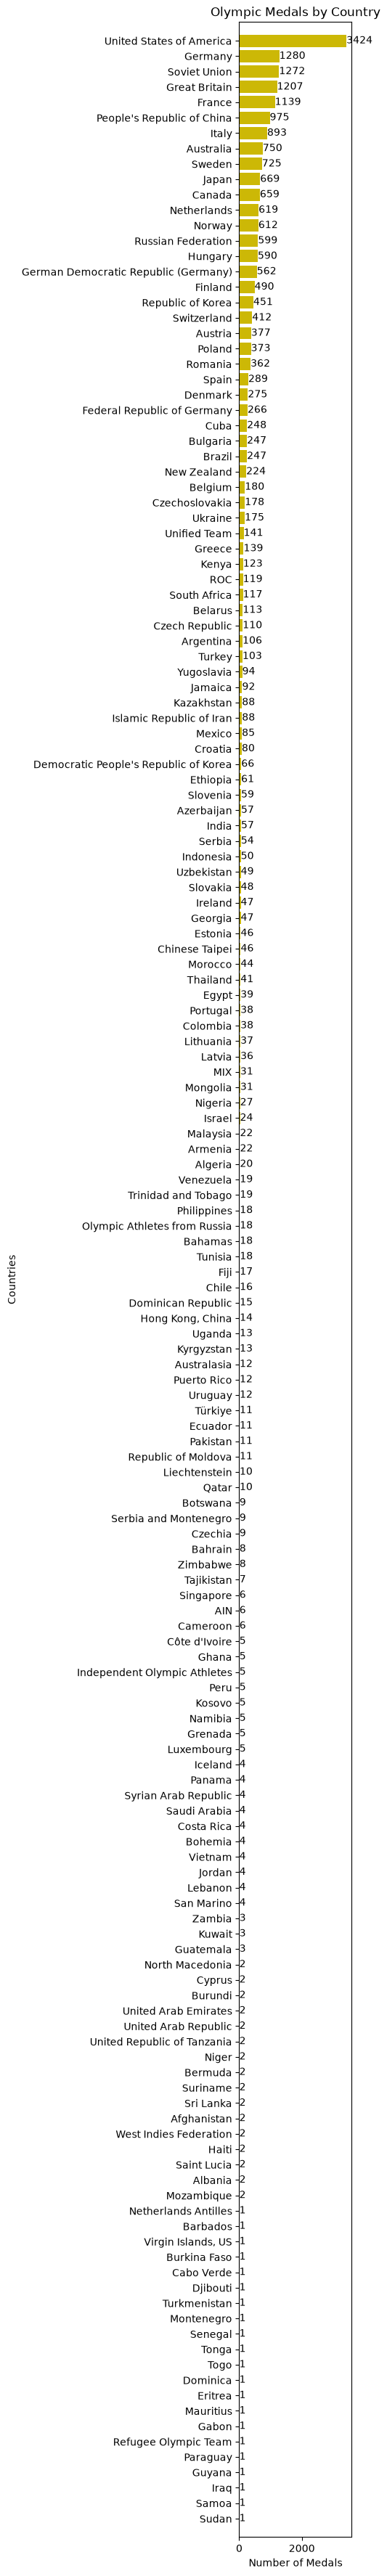

In [27]:
# Format the chart
plt.figure(figsize=(2,45))

# Format a bar chart
plt.barh(medalsByCountry.index, medalsByCountry.values, color='#ccb806')

plt.title("Olympic Medals by Country")
plt.xlabel('Number of Medals')
plt.ylabel('Countries')
plt.margins(y=0.005)

# Invert the 'Y' axis
plt.gca().invert_yaxis() # gca stands for "Get Current Axis"

# Add values to the chart
bars = plt.barh(medalsByCountry.index, medalsByCountry.values, color='#ccb806')

for bar in bars:
    plt.text(bar.get_width(), bar.get_y() + bar.get_height()/2,
             f'{bar.get_width():.0f}', # Position the text
             va='center') # Vertically align the text




plt.show()

## US Medals by type (Pie Chart)

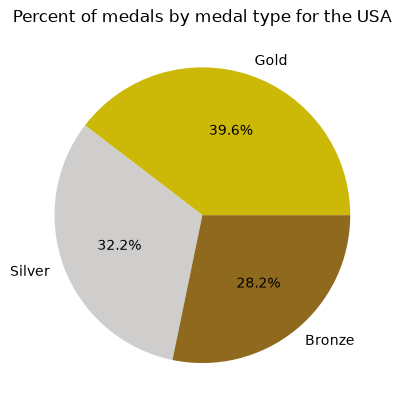

In [29]:
# Let's start by filtering the data
usResults = resultsdf[resultsdf['Country'] == 'United States of America']

# Calculate the number of Gold, Silver, and Bronze medals
medalCounts = usResults['Medal'].value_counts()

# Define colors for each medal
colors = ['#ccb806', '#cfcecc', '#8f691d'] # In order of Gold, Silver and Bronze

# Create Pie Chart
plt.pie(medalCounts.values, labels=medalCounts.index, autopct='%1.1f%%', colors=colors)

# Add a title
plt.title("Percent of medals by medal type for the USA")

plt.show()

## US Gold Medals by Year Line Chart

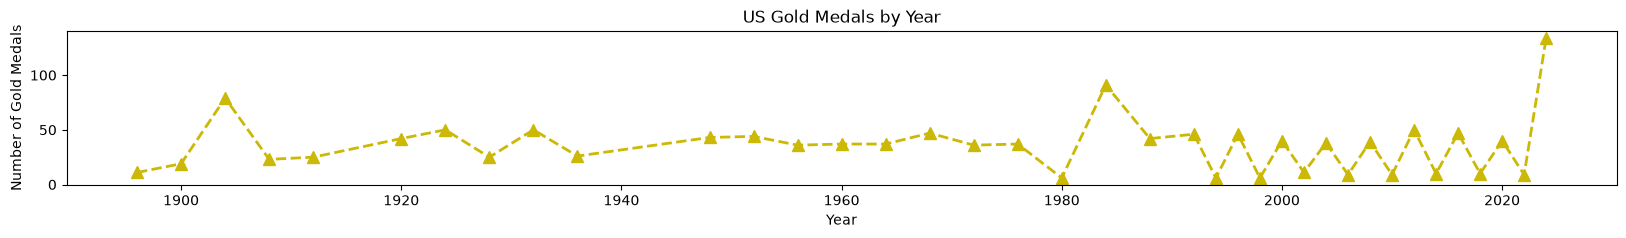

In [33]:
# Filter our data
usGold = resultsdf[(resultsdf.Country == 'United States of America') & (resultsdf.Medal == 'Gold')]

# Group the data to count the medals
usGoldYr = usGold.groupby('Year')['Medal'].count()

# Create my chart
plt.figure(figsize=(20,2))

# We can format how the line looks in the chart
plt.plot(usGoldYr.index, usGoldYr.values, color='#ccb806', linestyle='--', marker='^', linewidth='2', markersize=8)

plt.title("US Gold Medals by Year")
plt.xlabel('Year')
plt.ylabel('Number of Gold Medals')
plt.show()

## US Medals by type and by year.

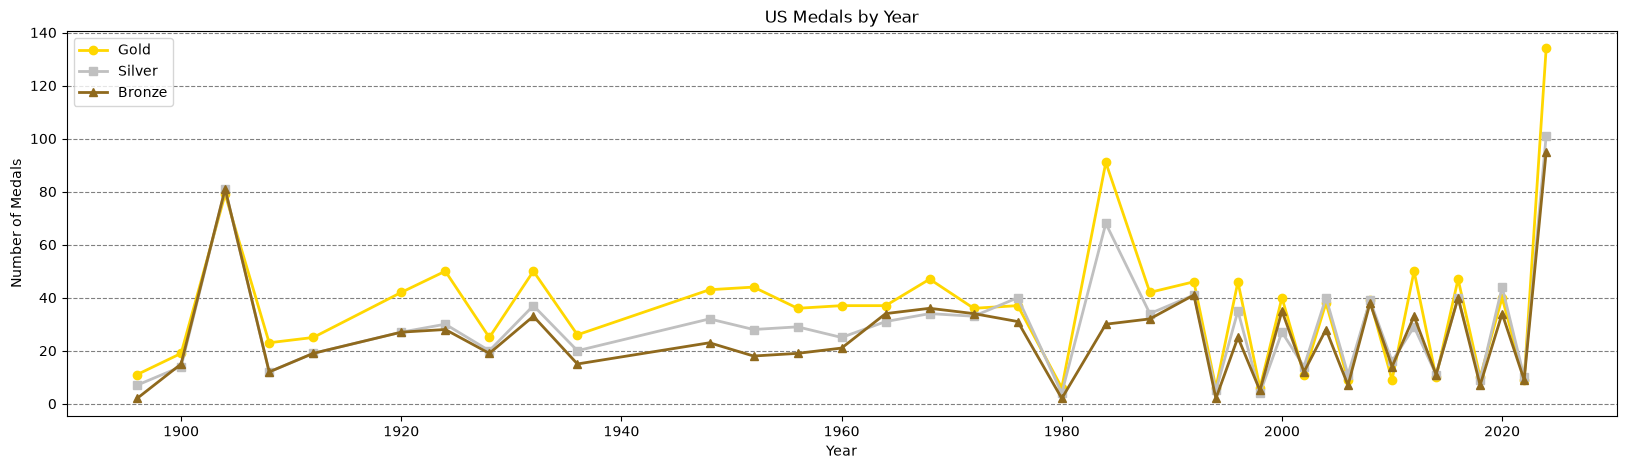

In [35]:
# Filter the data
usGold = resultsdf[(resultsdf.Country == 'United States of America') & (resultsdf.Medal == 'Gold')]
usSilver = resultsdf[(resultsdf.Country == 'United States of America') & (resultsdf.Medal == 'Silver')]
usBronze = resultsdf[(resultsdf.Country == 'United States of America') & (resultsdf.Medal == 'Bronze')]

# Group the data
usGoldYr = usGold.groupby('Year')['Medal'].count()
usSilverYr = usSilver.groupby('Year')['Medal'].count()
usBronzeYr = usBronze.groupby('Year')['Medal'].count()

# Create the chart
plt.figure(figsize=(20,5))

# Plot each medal separately
plt.plot(usGoldYr.index, usGoldYr.values, color = 'gold', linestyle='-', marker='o', linewidth=2, markersize=6, label='Gold')
plt.plot(usSilverYr.index, usSilverYr.values, color = 'silver', linestyle='-', marker='s', linewidth=2, markersize=6, label='Silver')
plt.plot(usBronzeYr.index, usBronzeYr.values, color = '#8f691d', linestyle='-', marker='^', linewidth=2, markersize=6, label='Bronze')

# Typical charty stuff
plt.title("US Medals by Year")
plt.xlabel('Year')
plt.ylabel("Number of Medals")
plt.legend()

# Add some grid lines
plt.grid(axis='y', linestyle='--', color='gray')

plt.show()

# Seaborn

## Compare Gold Medals between US, Sweden, Great Britain, and Canada.

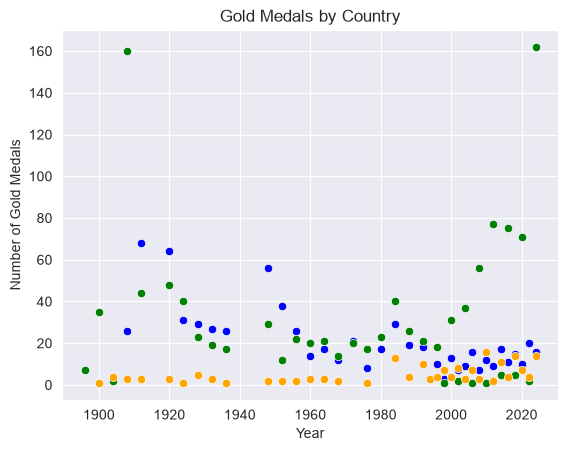

In [39]:
import seaborn as sns

medalsGold = resultsdf[(resultsdf.Country == 'United States of America') |
                       (resultsdf.Country == 'Sweden') |
                       (resultsdf.Country == 'Great Britain') |
                       (resultsdf.Country == 'Canada') &
                       (resultsdf.Medal == 'Gold')]


# Group our data
medalByYrCountry = medalsGold.groupby(['Year', 'Country']).size().reset_index(name='Gold Medals')

medalsByYr = medalsGold.groupby('Year')['Medal'].count()

# Create a pivot table to create a Matrix with years as rows and Countries as columns
medalsPivot = medalByYrCountry.pivot(index='Year', columns='Country', values='Gold Medals')

# Create our scatterplot
sns.scatterplot(data=medalByYrCountry[medalByYrCountry['Country'] =='United State of America'], x='Year', y='Gold Medals', color='red')
sns.scatterplot(data=medalByYrCountry[medalByYrCountry['Country'] =='Sweden'], x='Year', y='Gold Medals', color='blue')
sns.scatterplot(data=medalByYrCountry[medalByYrCountry['Country'] =='Great Britain'], x='Year', y='Gold Medals', color='green')
sns.scatterplot(data=medalByYrCountry[medalByYrCountry['Country'] =='Canada'], x='Year', y='Gold Medals', color='orange')

# Add style to our chart
sns.set_style('darkgrid')

# Style our chart
plt.title("Gold Medals by Country")
plt.xlabel('Year')
plt.ylabel('Number of Gold Medals')

plt.show()

## Built-in Seaborn data

In [40]:
dfCars = sns.load_dataset('car_crashes')

dfCars.head()

,total,speeding,alcohol,not_distracted,no_previous,ins_premium,ins_losses,abbrev
0,18.8,7.332,5.640,18.048,15.040,784.55,145.08,AL
1,18.1,7.421,4.525,16.290,17.014,1053.48,133.93,AK
2,18.6,6.510,5.208,15.624,17.856,899.47,110.35,AZ
3,22.4,4.032,5.824,21.056,21.280,827.34,142.39,AR
4,12.0,4.200,3.360,10.920,10.680,878.41,165.63,CA


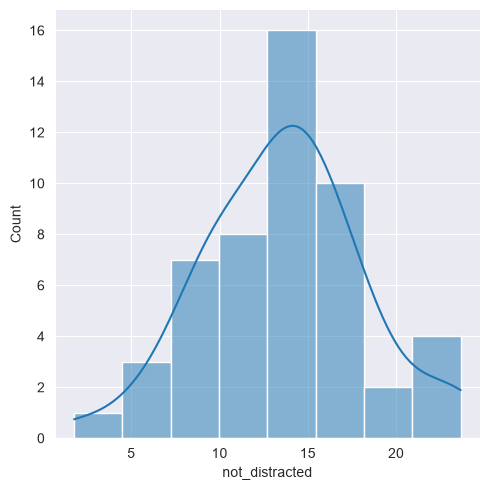

In [42]:
sns.displot(dfCars['not_distracted'], kde=True)

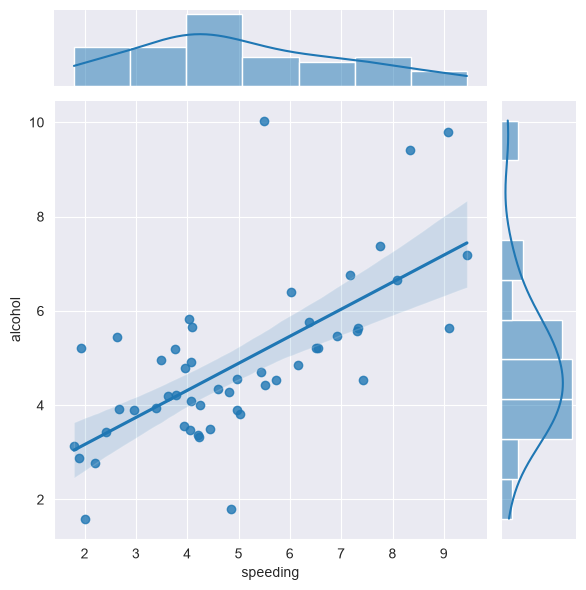

In [43]:
sns.jointplot(x='speeding', y='alcohol', data=dfCars, kind='reg')

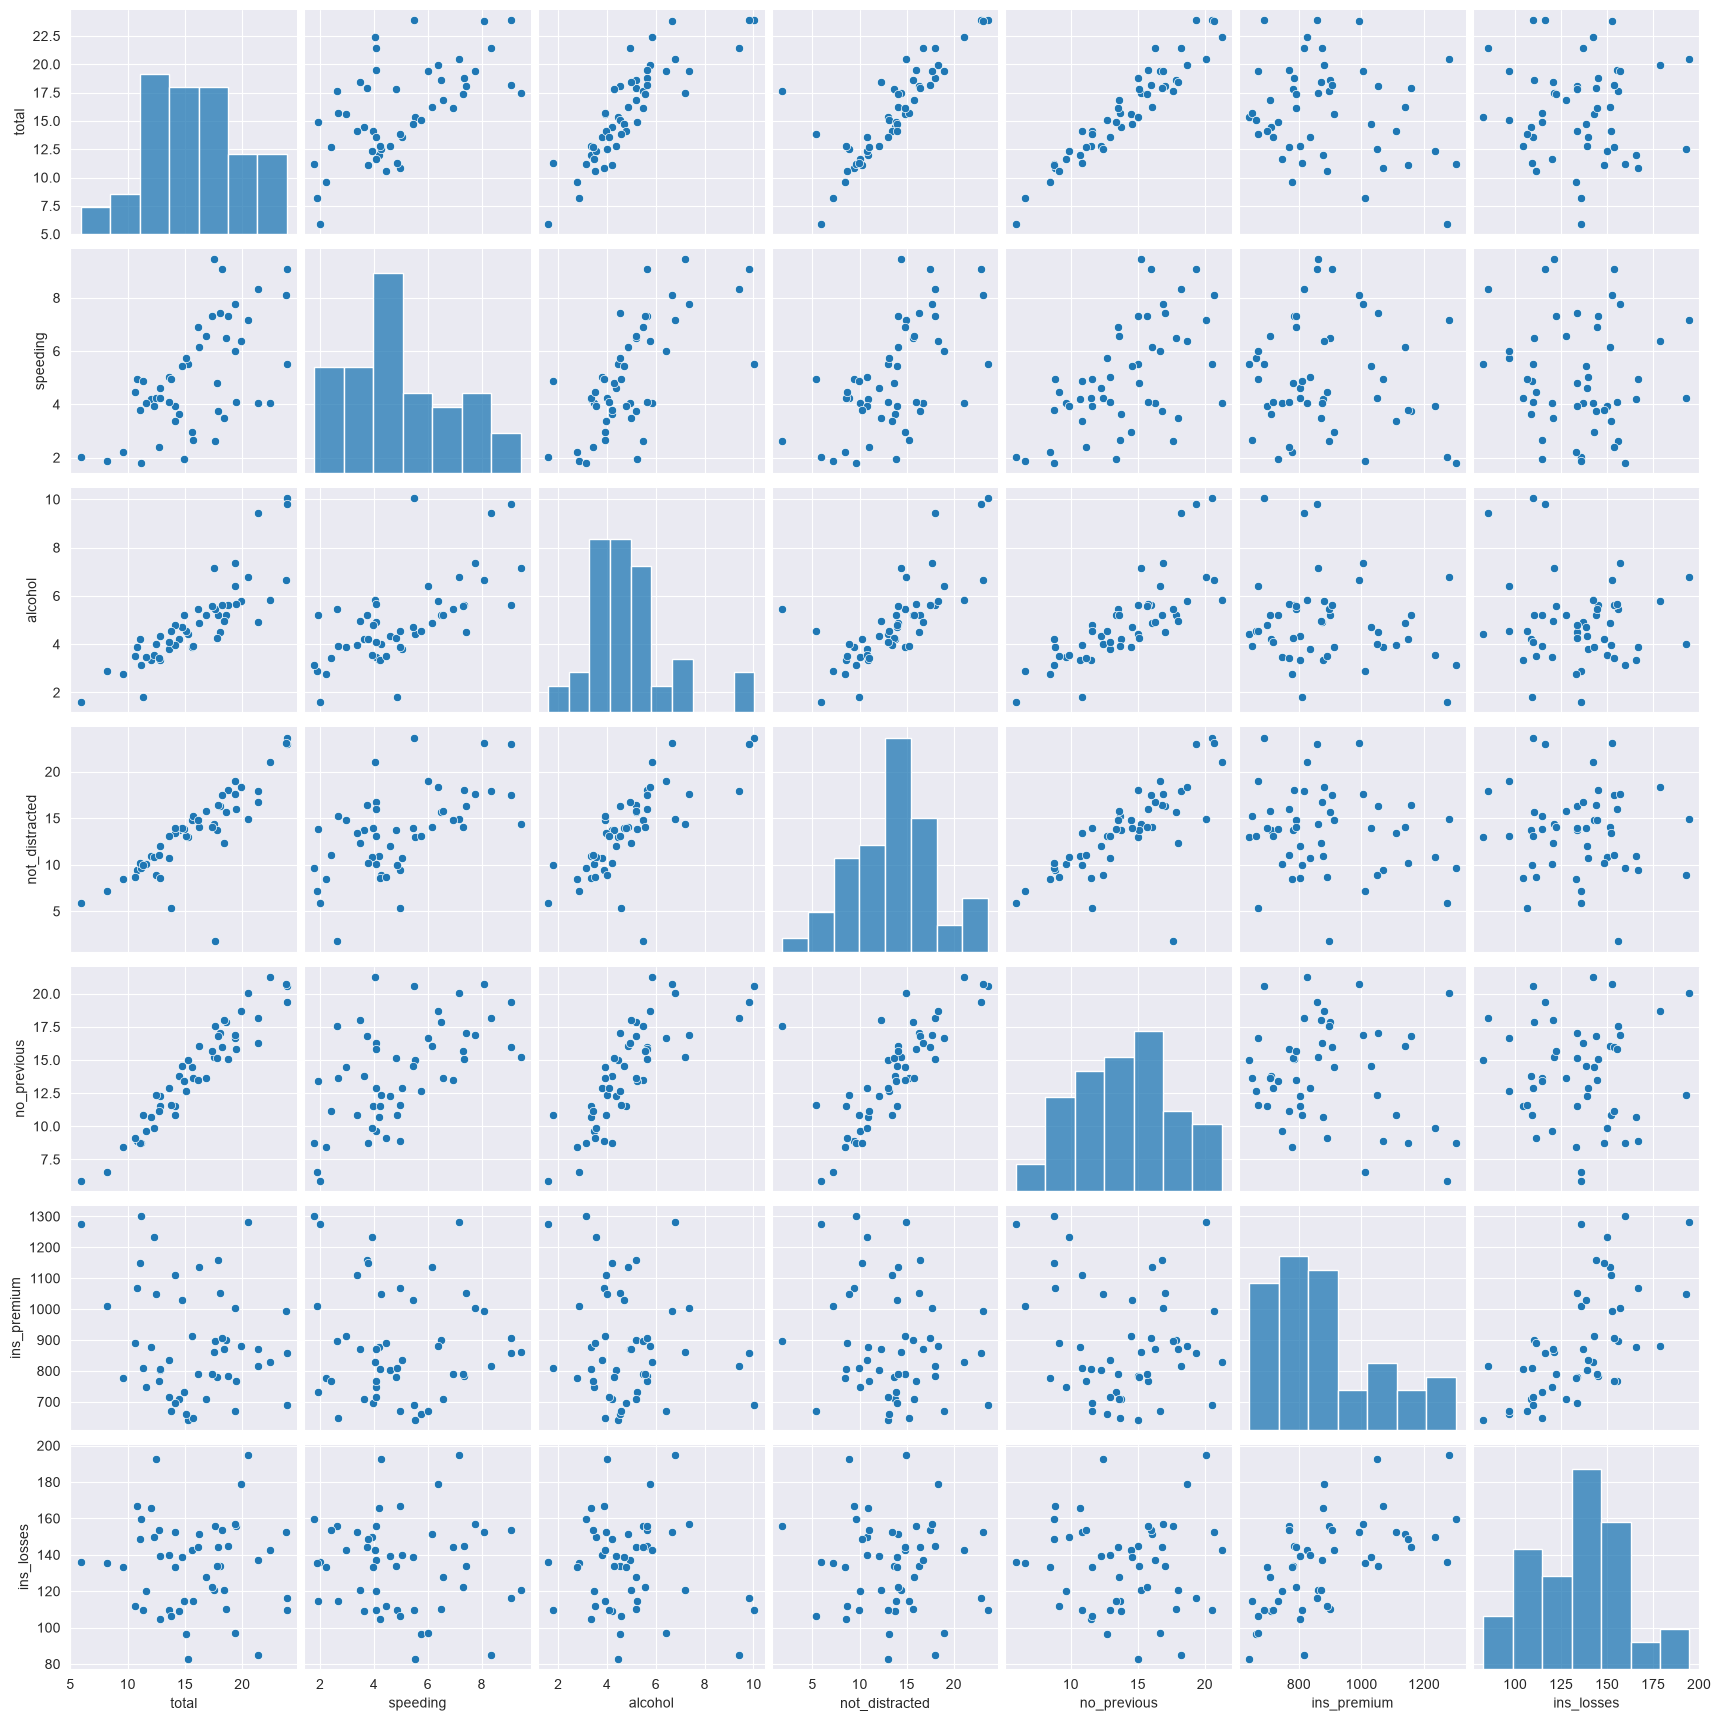

In [44]:
sns.pairplot(dfCars)

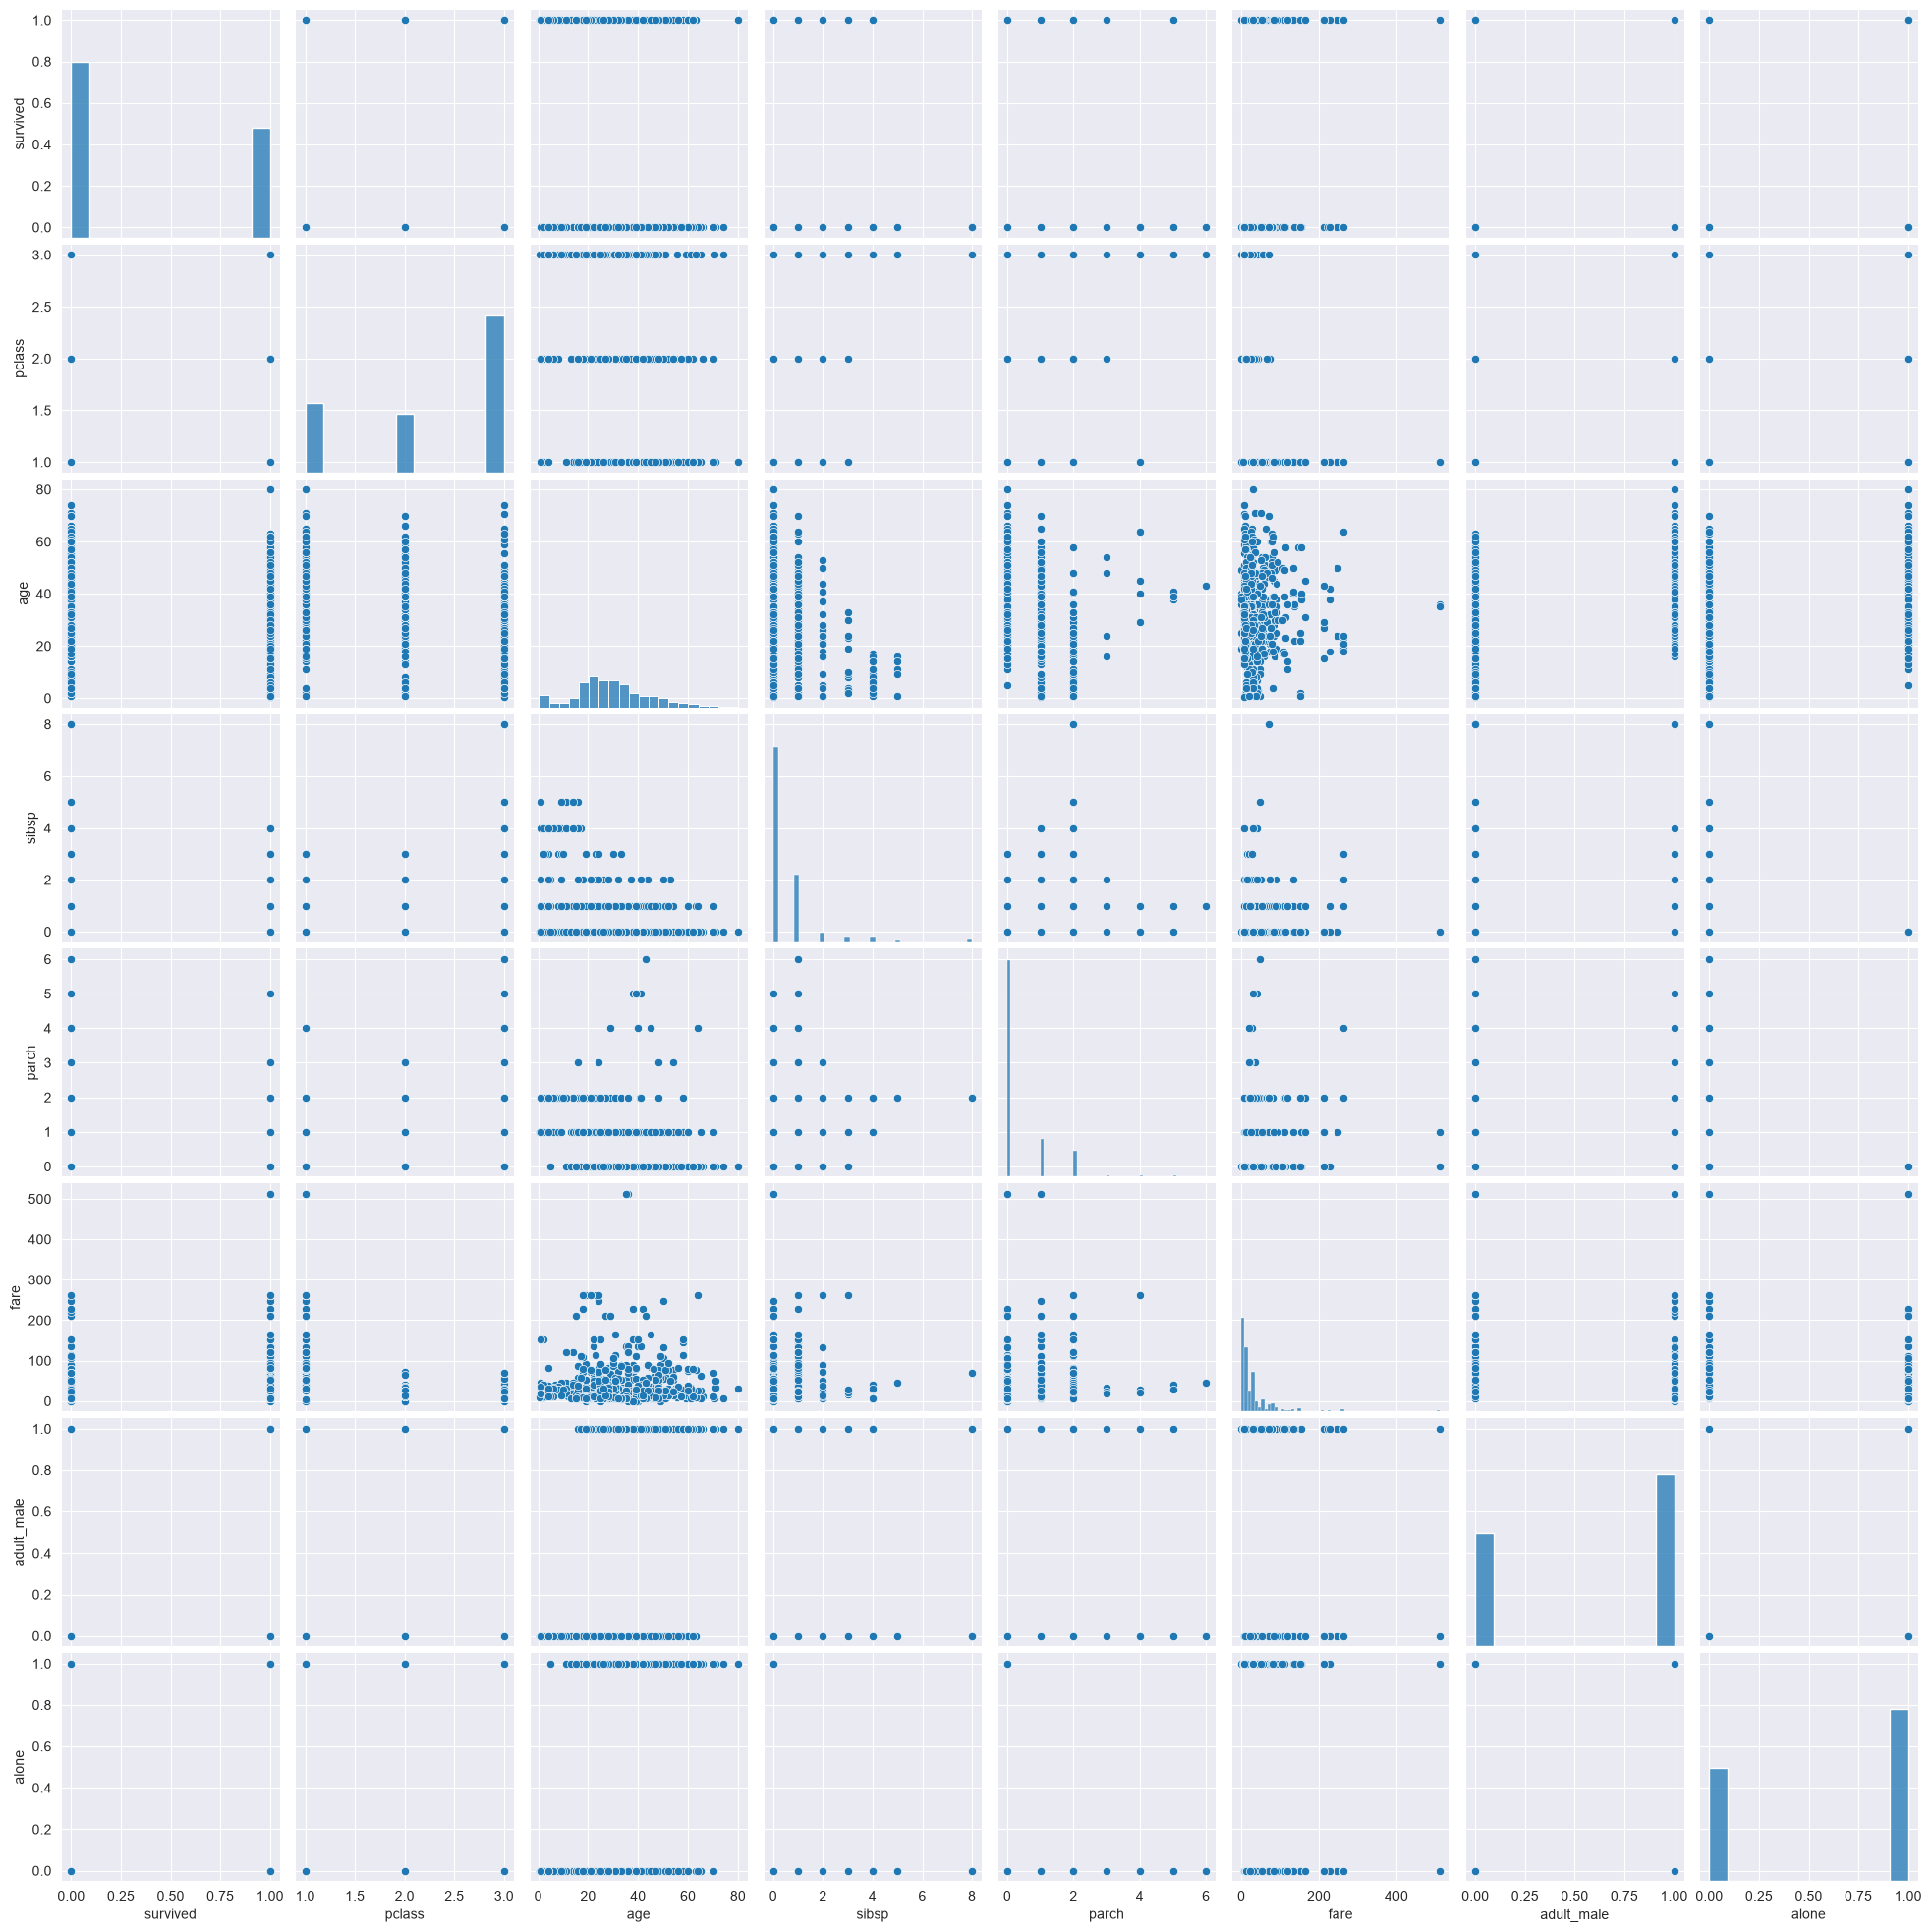

In [45]:
dfTitanic = sns.load_dataset('titanic')
sns.pairplot(dfTitanic)